In [ ]:
from pathlib import Path
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt
import re

SRC = Path('/Users/wm722/Documents/SCDs/results/Inference')
BOUNDS_CRS = 'EPSG:4326'

def parse_bounds(line):
    line = line.replace('Bounds of DEM: BoundingBox(', '').replace(')', '')
    return tuple(float(p.split('=')[1]) for p in line.split(', '))

def parse_crs(line):
    line = line.replace('CRS of DEM: ', '')
    return line

import geopandas as gpd
from shapely.geometry import box

def footprint(run):
    bounds_file = run / 'covered_bounds.txt'

    with open(bounds_file) as f:
        lines = f.readlines()

    bounds = parse_bounds(lines[1])
    crs = parse_crs(lines[2])

    geom = box(*bounds)

    return (
        gpd.GeoSeries([geom], crs=crs)
        .to_crs(BOUNDS_CRS)
        .iloc[0]
    )



# view

In [79]:
bounds = []
gdfs = []

for p in (SRC / 'Raw').glob('*/*/predictions.shp'):
    print(p)
    zone = re.search(r'Zone(\d+)', str(p.parent.name)).group(1)
    gdfs.append(gpd.read_file(p))
    bound = footprint(p.parent)
    bounds.append((zone, bound))

/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_47_To_52/Lats_47_52_Zone39_Inference_2/predictions.shp
/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_47_To_52/Lats_47_52_Zone40_Inference_2/predictions.shp
/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_47_To_52/Lats_47_52_Zone36_Inference_2/predictions.shp
/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_47_To_52/Lats_47_52_Zone41_Inference_2/predictions.shp
/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_47_To_52/Lats_47_52_Zone38_Inference_2/predictions.shp
/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_47_To_52/Lats_47_52_Zone37_Inference_2/predictions.shp
/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_52_To_56/Zone41_Inference_obj_3/predictions.shp
/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_52_To_56/Zone40_Inference_obj_3/predictions.shp
/Users/wm722/Documents/SCDs/results/Inference/Raw/Latitudes_52_To_56/Zone45_Inference_obj_3/pr

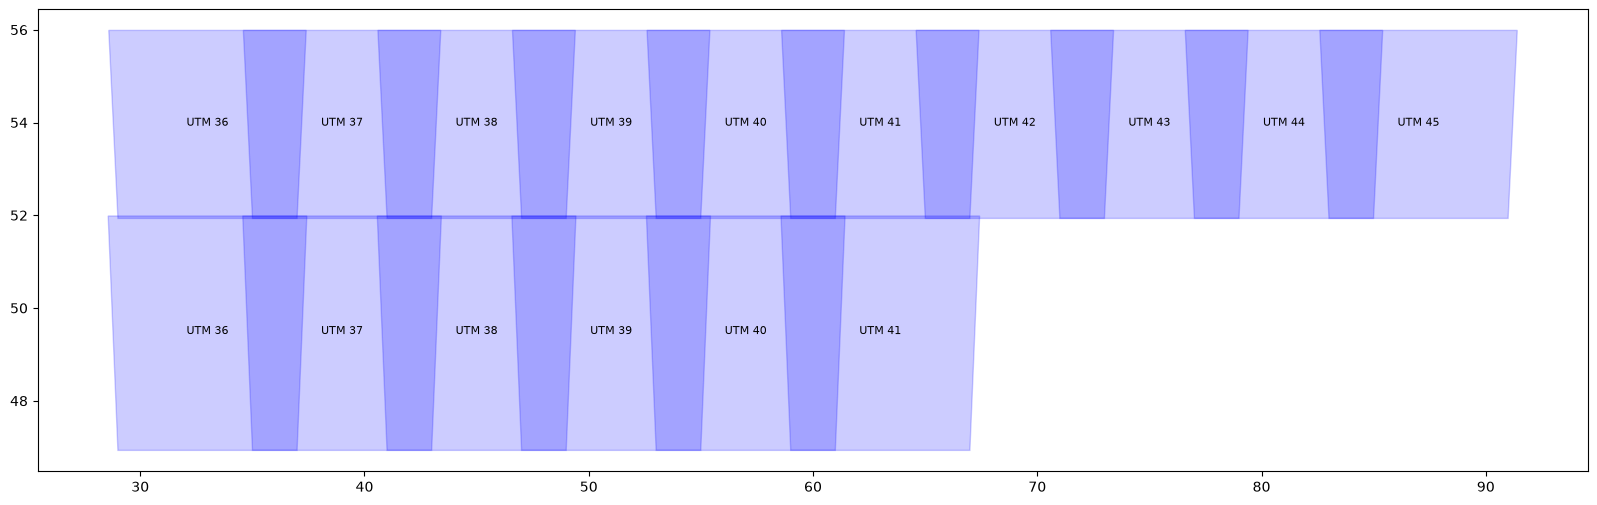

In [77]:
fig, ax = plt.subplots(figsize=(20, 6))

for zone, rect in bounds:
    x, y = rect.exterior.xy
    ax.fill(x, y, color='blue', alpha=0.2, linewidth=1, edgecolor='blue')
    ax.text(rect.centroid.x, rect.centroid.y, f'UTM {zone}', fontsize=8, ha='center', va='center')

In [89]:
print(bounds)

[('39', <POLYGON ((54.995 46.93, 55.429 51.985, 46.571 51.985, 47.005 46.93, 54.995 ...>), ('40', <POLYGON ((60.995 46.93, 61.429 51.985, 52.571 51.985, 53.005 46.93, 60.995 ...>), ('36', <POLYGON ((36.995 46.93, 37.429 51.985, 28.571 51.985, 29.005 46.93, 36.995 ...>), ('41', <POLYGON ((66.995 46.93, 67.429 51.985, 58.571 51.985, 59.005 46.93, 66.995 ...>), ('38', <POLYGON ((48.995 46.93, 49.429 51.985, 40.571 51.985, 41.005 46.93, 48.995 ...>), ('37', <POLYGON ((42.995 46.93, 43.429 51.985, 34.571 51.985, 35.005 46.93, 42.995 ...>), ('41', <POLYGON ((66.994 51.932, 67.402 55.986, 58.598 55.986, 59.006 51.932, 66.99...>), ('40', <POLYGON ((60.994 51.932, 61.402 55.986, 52.598 55.986, 53.006 51.932, 60.99...>), ('45', <POLYGON ((90.994 51.932, 91.402 55.986, 82.598 55.986, 83.006 51.932, 90.99...>), ('38', <POLYGON ((48.994 51.932, 49.402 55.986, 40.598 55.986, 41.006 51.932, 48.99...>), ('42', <POLYGON ((72.994 51.932, 73.402 55.986, 64.598 55.986, 65.006 51.932, 72.99...>), ('37', <P

In [112]:
gdfs[0]

,object_id,score,area_m2,circ,depth_m,dw_ratio,elongation,eccentrici,embedding,emb_0,...,emb_27,emb_28,emb_29,emb_30,emb_31,emb_32,emb_33,emb_34,emb_35,geometry
0,345,0.997321,280600.0,0.536256,-4.395531,-0.007354,2.081674,0.877059,NaN,1.077126,...,0.258713,0.918777,0.132640,0.309004,0.841305,-0.500298,-0.056515,1.481776,0.036725,"POLYGON ((370664.989 5744501.79, 370944.989 57..."
1,356,0.754079,81100.0,0.750816,-3.672150,-0.011428,1.244402,0.595171,NaN,1.933194,...,0.125306,1.431789,0.493533,0.371107,1.286115,0.038976,-0.016073,0.983453,-0.235663,"POLYGON ((373344.989 5743571.79, 373444.989 57..."
2,417,1.000000,83025.0,0.716940,-2.335148,-0.007182,1.933881,0.855928,NaN,1.467511,...,2.074537,1.458653,0.000000,2.185818,1.612096,-0.349797,-0.284644,0.992870,0.048203,"POLYGON ((406699.989 5739961.79, 406719.989 57..."
3,560,0.842821,24925.0,0.911263,-4.584496,-0.025735,1.142050,0.483004,NaN,0.565709,...,0.128311,0.350763,0.103388,0.330699,0.344150,0.195854,0.055709,0.509835,-1.192287,"POLYGON ((582674.989 5729171.79, 582759.989 57..."
4,564,0.802277,22600.0,0.800686,-4.440628,-0.026178,1.524050,0.754634,NaN,0.460374,...,0.152319,0.345651,0.000000,0.283110,0.206916,0.864622,0.168191,0.470528,-1.221923,"POLYGON ((749284.989 5729061.79, 749374.989 57..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6064,28409,0.986816,77500.0,0.723793,-0.736063,-0.002343,1.780661,0.827416,NaN,1.974566,...,0.461608,1.561286,0.354448,0.774367,1.474268,-0.474318,-0.137204,0.965225,0.371753,"POLYGON ((522884.989 5208836.79, 522959.989 52..."
6065,28453,0.894680,28675.0,0.815919,-2.702362,-0.014143,1.674616,0.802128,NaN,0.720378,...,0.157942,0.517205,0.000000,0.233271,0.499205,-0.059275,0.099368,0.566095,-0.417214,"POLYGON ((410984.989 5207721.79, 411099.989 52..."
6066,28456,0.925053,31550.0,0.844719,-3.175165,-0.015842,1.568374,0.770365,NaN,0.448255,...,0.212843,0.382392,0.000000,0.210437,0.348522,0.287584,0.066475,0.604450,-0.530830,"POLYGON ((355129.989 5207611.79, 355184.989 52..."
6067,28472,0.977468,39500.0,0.557190,-0.509830,-0.002273,3.237568,0.951103,NaN,0.000000,...,0.495738,0.000000,0.000000,0.591988,0.111363,-0.473274,-0.318545,0.694661,0.376421,"POLYGON ((602194.989 5207401.79, 602244.989 52..."


In [123]:
def iou(a, b):
    """
    Computes the Intersection over Union (IoU) of two polygons.
    """
    intersection = a.intersection(b).area
    union = a.union(b).area

    return intersection / union if union > 0 else 0


def overlap_vote(gdf1, gdf2, bounds1, bounds2, threshold=0.25):

    target_crs = "EPSG:6933"

    # Reproject to common equal-area CRS
    gdf1 = gdf1.to_crs(target_crs)
    gdf2 = gdf2.to_crs(target_crs)

    bounds1 = gpd.GeoSeries(
        [bounds1], crs="EPSG:4326"
    ).to_crs(target_crs).iloc[0]

    bounds2 = gpd.GeoSeries(
        [bounds2], crs="EPSG:4326"
    ).to_crs(target_crs).iloc[0]

    if not bounds1.intersects(bounds2):
        return gdf1, gdf2

    overlap = bounds1.intersection(bounds2)

    removed_from_gdf1 = set()
    removed_from_gdf2 = set()

    for idx1, object in gdf1.iterrows():

        geom1 = object.geometry

        if idx1 in removed_from_gdf1 or not geom1.intersects(overlap):
            continue

        for idx2, other in gdf2.iterrows():

            if idx2 in removed_from_gdf2:
                continue

            geom2 = other.geometry

            if not geom2.intersects(overlap):
                continue

            if not geom1.intersects(geom2):
                continue

            # Clip to shared coverage
            a = geom1.intersection(overlap)
            b = geom2.intersection(overlap)

            if a.is_empty or b.is_empty:
                continue

            if iou(a, b) > threshold:

                if object.score >= other.score:
                    removed_from_gdf2.add(idx2)
                else:
                    removed_from_gdf1.add(idx1)
                    break

            elif geom1.contains(geom2):
                removed_from_gdf2.add(idx2)

            elif geom2.contains(geom1):
                removed_from_gdf1.add(idx1)
                break

    gdf1 = gdf1.drop(index=list(removed_from_gdf1))
    gdf2 = gdf2.drop(index=list(removed_from_gdf2))

    print(
        f"Removed {len(removed_from_gdf1)} objects from gdf1 "
        f"and {len(removed_from_gdf2)} objects from gdf2."
    )

    return gdf1, gdf2

In [ ]:
from itertools import combinations

for i, j in combinations(range(len(gdfs)), 2):
    gdfs[i], gdfs[j] = overlap_vote(
        gdfs[i], gdfs[j],
        bounds[i][1], bounds[j][1])

Removed 134 objects from gdf1 and 244 objects from gdf2.
